
# 📊 Descriptive Statistics
### Mean, Median, Mode, Variance & Standard Deviation


**Learning Objectives**
- Understand measures of *central tendency*: Mean, Median, Mode
- Understand measures of *spread*: Variance, Standard Deviation
- Learn how outliers affect different statistics
- Visualize these concepts using the `tips` dataset from Seaborn

---
We will use the built-in **`tips`** dataset from Seaborn, which contains information about restaurant bills, tips, and customer details.


## 1. Setup & Load Data

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

sns.set_theme(style="whitegrid")
%matplotlib inline

# Load the built-in 'tips' dataset
df = sns.load_dataset("tips")
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [2]:
# Basic information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [3]:
# Quick statistical summary (pandas gives us most of what we need!)
df.describe()

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000



## 2. Measures of Central Tendency

Central tendency tells us about the "center" or "typical value" of a dataset.

| Measure | Definition | Best Used When |
|---|---|---|
| **Mean** | Sum of all values divided by number of values | Data is roughly symmetric, no extreme outliers |
| **Median** | Middle value when data is sorted | Data is skewed or has outliers |
| **Mode** | Most frequently occurring value | Categorical / discrete data |

We'll explore these using the `total_bill` column.


In [4]:
bills = df["total_bill"]

# ---- MEAN ----
mean_manual = bills.sum() / len(bills)
mean_numpy = np.mean(bills)
mean_pandas = bills.mean()

print(f"Mean (manual)  : {mean_manual:.4f}")
print(f"Mean (numpy)   : {mean_numpy:.4f}")
print(f"Mean (pandas)  : {mean_pandas:.4f}")

Mean (manual)  : 19.7859
Mean (numpy)   : 19.7859
Mean (pandas)  : 19.7859


In [5]:
# ---- MEDIAN ----
median_numpy = np.median(bills)
median_pandas = bills.median()

print(f"Median (numpy) : {median_numpy:.4f}")
print(f"Median (pandas): {median_pandas:.4f}")

Median (numpy) : 17.7950
Median (pandas): 17.7950


In [6]:
# ---- MODE ----
# Mode is more meaningful for discrete/categorical data.
# Let's check the mode of 'size' (number of people at the table)
mode_size = df["size"].mode()
print("Mode of table size:", mode_size.values)


Mode of table size: [2]



## 3. Visualizing Mean vs Median

A histogram with mean and median marked helps us understand the **shape (skewness)** of the data.

- If **mean > median** → right-skewed (long tail to the right)
- If **mean < median** → left-skewed
- If **mean ≈ median** → roughly symmetric


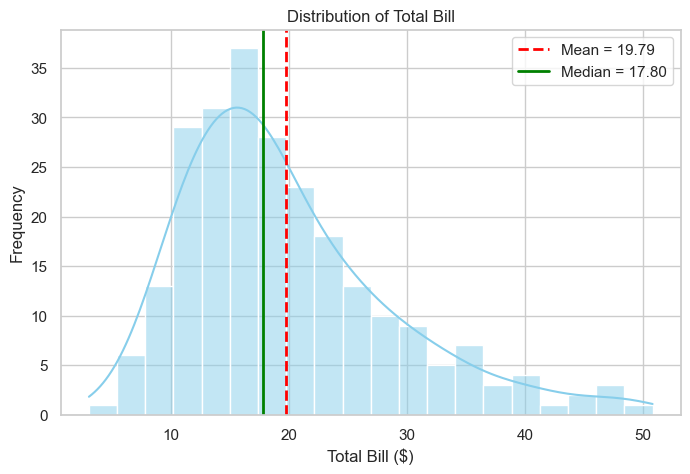

Notice: the distribution is slightly right-skewed (mean > median),
because a few large bills pull the mean upward.


In [7]:
plt.figure(figsize=(8, 5))
sns.histplot(bills, kde=True, bins=20, color="skyblue")

plt.axvline(mean_pandas, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pandas:.2f}")
plt.axvline(median_pandas, color="green", linestyle="-", linewidth=2, label=f"Median = {median_pandas:.2f}")

plt.title("Distribution of Total Bill")
plt.xlabel("Total Bill ($)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

print("Notice: the distribution is slightly right-skewed (mean > median),")
print("because a few large bills pull the mean upward.")


## 4. Effect of Outliers on Mean vs Median

Let's see what happens when we add an extreme outlier (a huge bill of \$500) to the dataset.


In [8]:
bills_with_outlier = pd.concat([bills, pd.Series([500])], ignore_index=True)

comparison = pd.DataFrame({
    "Without Outlier": [bills.mean(), bills.median()],
    "With Outlier":    [bills_with_outlier.mean(), bills_with_outlier.median()]
}, index=["Mean", "Median"])

comparison["Change"] = comparison["With Outlier"] - comparison["Without Outlier"]
comparison

,Without Outlier,With Outlier,Change
Mean,19.785943,21.746,1.960057
Median,17.795000,17.810,0.015000



**Observation:** Notice how the **mean shifts significantly** with a single outlier, while the **median barely moves**. This is why median is preferred for skewed data like income, house prices, hospital bills, etc.



## 5. Measures of Spread: Variance & Standard Deviation

These tell us **how spread out** the data is around the mean.

$$\text{Population Variance: } \sigma^2 = \frac{1}{N}\sum_{i=1}^{N}(x_i - \mu)^2$$

$$\text{Sample Variance: } s^2 = \frac{1}{n-1}\sum_{i=1}^{n}(x_i - \bar{x})^2$$

$$\text{Standard Deviation: } \sigma \text{ (or } s\text{)} = \sqrt{\text{Variance}}$$

> **Key Point:** When working with a *sample* (a subset of data meant to represent a population), we divide by `n-1` instead of `n`. This is called **Bessel's correction** and gives an unbiased estimate of the population variance.

In Python:
- `np.var(data)` → uses `ddof=0` (population, divides by N) by default
- `pd.Series.var()` → uses `ddof=1` (sample, divides by n-1) by default


In [9]:
n = len(bills)
mean_val = bills.mean()

# ---- VARIANCE (manual calculation) ----
sum_sq_dev = ((bills - mean_val) ** 2).sum()

population_variance = sum_sq_dev / n
sample_variance = sum_sq_dev / (n - 1)

print(f"Sum of squared deviations : {sum_sq_dev:.2f}")
print(f"Population Variance (N)   : {population_variance:.4f}")
print(f"Sample Variance (n-1)     : {sample_variance:.4f}")

print("\n--- Verifying with built-in functions ---")
print(f"numpy var (ddof=0)   : {np.var(bills):.4f}")
print(f"numpy var (ddof=1)   : {np.var(bills, ddof=1):.4f}")
print(f"pandas var (default) : {bills.var():.4f}")

Sum of squared deviations : 19258.46
Population Variance (N)   : 78.9281
Sample Variance (n-1)     : 79.2529

--- Verifying with built-in functions ---
numpy var (ddof=0)   : 78.9281
numpy var (ddof=1)   : 79.2529
pandas var (default) : 79.2529


In [10]:
# ---- STANDARD DEVIATION ----
population_std = np.sqrt(population_variance)
sample_std = np.sqrt(sample_variance)

print(f"Population Std Dev : {population_std:.4f}")
print(f"Sample Std Dev      : {sample_std:.4f}")
print(f"pandas std()        : {bills.std():.4f}")  # uses ddof=1 by default

Population Std Dev : 8.8842
Sample Std Dev      : 8.9024
pandas std()        : 8.9024



## 6. Group-wise Descriptive Statistics

Real-world analysis often involves comparing groups. Let's compare `total_bill` statistics across **days of the week** and **gender**.


In [11]:
day_stats = df.groupby("day")["total_bill"].agg(["mean", "median", "var", "std", "count"])
day_stats

C:\Users\hi\AppData\Local\Temp\ipykernel_16936\366422963.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  day_stats = df.groupby("day")["total_bill"].agg(["mean", "median", "var", "std", "count"])


,mean,median,var,std,count
day,,,,,
Thur,17.682742,16.20,62.191683,7.886170,62
Fri,17.151579,15.38,68.934158,8.302660,19
Sat,20.441379,18.24,89.878338,9.480419,87
Sun,21.410000,19.63,78.006376,8.832122,76


In [12]:
gender_stats = df.groupby("sex")["total_bill"].agg(["mean", "median", "var", "std"])
gender_stats

C:\Users\hi\AppData\Local\Temp\ipykernel_16936\2710058188.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  gender_stats = df.groupby("sex")["total_bill"].agg(["mean", "median", "var", "std"])


,mean,median,var,std
sex,,,,
Male,20.744076,18.35,85.497185,9.246469
Female,18.056897,16.40,64.147429,8.009209



## 7. Visualizing Spread: Box Plots

A **box plot** visually summarizes:
- Median (middle line)
- Interquartile Range / IQR (the box: 25th to 75th percentile)
- Whiskers (typical range)
- Outliers (individual points beyond whiskers)

This connects directly to variance/std — wider boxes = more spread.


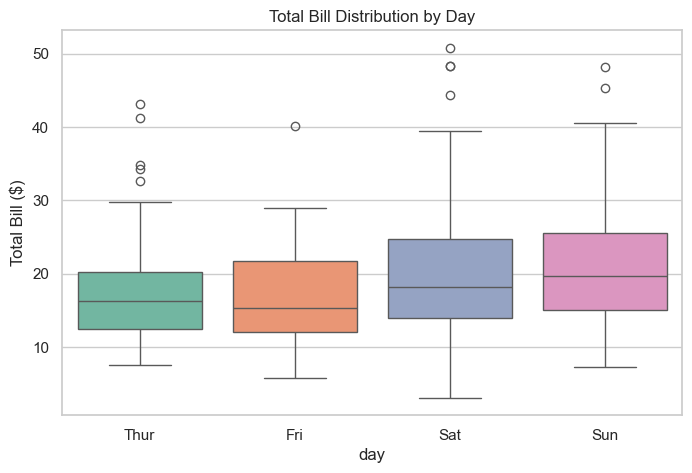

In [13]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="day", y="total_bill", hue="day", palette="Set2", legend=False)
plt.title("Total Bill Distribution by Day")
plt.ylabel("Total Bill ($)")
plt.show()

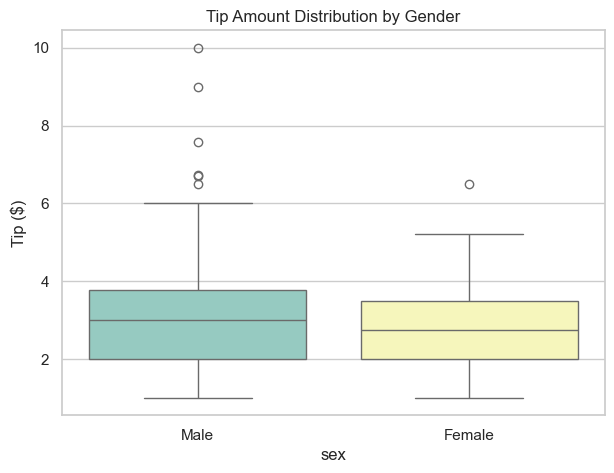

In [14]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="sex", y="tip", hue="sex", palette="Set3", legend=False)
plt.title("Tip Amount Distribution by Gender")
plt.ylabel("Tip ($)")
plt.show()


## 8. Coefficient of Variation (Bonus Concept)

Standard deviation alone doesn't tell us if spread is "large" — it depends on scale. The **Coefficient of Variation (CV)** expresses std as a percentage of the mean, allowing comparison across variables with different units/scales.

$$CV = \frac{\sigma}{\mu} \times 100\%$$


In [15]:
for col in ["total_bill", "tip"]:
    cv = (df[col].std() / df[col].mean()) * 100
    print(f"Coefficient of Variation for '{col}': {cv:.2f}%")

Coefficient of Variation for 'total_bill': 44.99%
Coefficient of Variation for 'tip': 46.15%



## 9. Summary

| Concept | Formula | Python |
|---|---|---|
| Mean | $\frac{\sum x_i}{n}$ | `df.mean()` |
| Median | Middle value (sorted) | `df.median()` |
| Mode | Most frequent value | `df.mode()` |
| Variance (sample) | $\frac{\sum(x_i-\bar{x})^2}{n-1}$ | `df.var()` |
| Std Dev (sample) | $\sqrt{\text{Variance}}$ | `df.std()` |

**Key Takeaways:**
1. Mean is sensitive to outliers; median is robust.
2. Variance/std measure spread — larger value means more variability.
3. Always visualize data (histograms, box plots) alongside summary statistics — numbers alone can be misleading!

---

## 10. Practice Exercises (for students)

1. Load the `penguins` dataset (`sns.load_dataset("penguins")`). Compute mean, median, and standard deviation of `body_mass_g`.
2. Compare the mean and median of `flipper_length_mm` grouped by `species`. Which species shows the most variability?
3. Add an artificial outlier of 10,000g to `body_mass_g` and observe the effect on mean vs median.
4. Create a box plot of `bill_length_mm` grouped by `island`. Which island shows the widest spread?
